# Praktikum 06 — Pipeline dan Evaluasi Model Preeklamsia (PE)

**Rangkaian:** *From Data to Machine Learning* — lanjutan Praktikum 05  
**Fokus:** *supervised learning*, `Pipeline`, `DecisionTreeClassifier`, validasi, evaluasi data tidak seimbang, interpretasi dan audit batas penggunaan.  
**Estimasi belajar:** 120–150 menit (dapat dibagi menjadi dua pertemuan).  
**Prasyarat:** Praktikum 01–05, terutama train–test split, imputasi, One-Hot Encoding, serta dasar confusion matrix.

> **PENTING:** Ini adalah studi kasus pembelajaran menggunakan data berlabel. **Bukan sistem skrining, diagnosis, atau pendukung keputusan klinis**. Identitas pasien, independensi antarbaris, ketepatan waktu pencatatan prediktor dan label, dan validitas eksternal belum terverifikasi. Jangan menggunakan prediksi atau probabilitas model untuk keputusan layanan kesehatan.

**Bahan utama:** `data_bersih.csv` (hasil Praktikum 05) beserta workbook asli `dataKasus-1.xlsx` dan helper resmi paket `pe_workflow.py` untuk pengecekan konsistensi. Notebook ini **tidak menghapus duplikat profil fitur** maupun mengubah definisi PE/Non PE.

## A. Peta belajar dan capaian pembelajaran

| Tahap | Mahasiswa mempelajari | Bukti penguasaan |
|---|---|---|
| 1 | Memahami dataset siap preprocessing | Menjelaskan 8 prediktor, target, distribusi kelas |
| 2 | Split dan pencegahan data leakage | Menunjukkan fungsi `fit` hanya pada train |
| 3 | Merangkai `ColumnTransformer` + `Pipeline` | Membentuk model siap menerima data mentah (8 kolom) |
| 4 | Membuat baseline dan Decision Tree | Membandingkan prediksi mayoritas vs pohon |
| 5 | Mengevaluasi kelas minoritas | Menghitung TP, FN, FP, TN, recall, precision, specificity, F1 |
| 6 | Memvalidasi konfigurasi | Memilih hyperparameter dengan CV di train saja |
| 7 | Menafsirkan dan mengaudit batasan model | Mengidentifikasi error dan risiko inferensi klinis |

**Artefak akhir:** `metrik_perbandingan.csv`, `prediksi_test.csv`, `ringkasan_cv.csv`, `laporan_praktikum06.json`, dan grafik pada tampilan notebook. Persistensi `.joblib` menjadi kompetensi utama **Praktikum 07**.

## B. Konsep dasar dan rancangan eksperimen

- **Target positif (`1`):** kelompok label `PE`, `PEB`, `Eklamsia`, `PE gemelli`, `PEB impending eklampsi`; **target negatif (`0`):** `Non PE`. Penyatuan label mengikuti paket sumber dan **bukan** penyamaan makna klinis seluruh kategori.
- **Prediktor utama:** `USIA`, `PARITAS`, `JARAK KELAHIRAN`, `RIW HIPERTENSI`, `OBESITAS`, `RIW DM`, `RIW HIPERTENSI/PE DALAM KELUARGA`, `SOSEK RENDAH`.
- `RIW PE` **tidak** dimasukkan ke prediktor karena definisi, temporalitas dan kemungkinan kebocoran target belum terverifikasi. Kolom pengenal (nama/nomor) juga tidak digunakan.
- **Unit evaluasi sebenarnya:** baris sumber (row-level), **bukan** pasien independen yang terverifikasi.
- **Rancangan:** split terstratifikasi → fit pipeline pada train → eksperimen baseline & Decision Tree → CV untuk pemilihan parameter pada train → *sekali* evaluasi test → audit error.

**Peringatan:** Split baris yang membagi data seorang pasien ke train dan test dapat menggelembungkan hasil. Jika ID pasien dan waktu pengukuran tersedia pada studi nyata, desain split harus ditinjau ulang (patient-level, temporal, atau site holdout).

### B1. Istilah utama

| Istilah | Makna dalam notebook |
|---|---|
| `X` | Matriks 8 prediktor yang belum diimputasi/di-encode |
| `y` | Target biner (`0` Non PE; `1` kelompok PE) |
| `X_train`, `X_test` | Fitur yang dipisahkan sebelum `fit` statistik preprocessing |
| `fit` | Belajar median/modus/kategori pada train; melatih pohon keputusan |
| `transform` | Menerapkan aturan preprocessing terpelajar pada data lain |
| `predict` | Memilih label 0 atau 1 dari model |
| `predict_proba` | Menghasilkan skor berdasarkan estimasi model, **bukan risiko klinis yang terkalibrasi** |
| *Baseline* | Model pembanding sederhana tanpa informasi prediktor |
| *Cross-validation* | Menguji variasi model melalui subset train tanpa memakai test |
| *Leakage* | Informasi yang tidak semestinya diketahui saat training masuk ke pipeline |

## C. Persiapan notebook dan pemeriksaan berkas

Ekstrak ZIP sampai struktur berikut tersedia:

```text
06_Pipeline_dan_Evaluasi_PE_Modul_Final_dan_Jawaban.ipynb
studi_kasus/
  data/
    asli/dataKasus-1.xlsx
    hasil/data_bersih.csv
  python/pe_workflow.py
  hasil/           # diisi otomatis
requirements.txt
```

Jalankan sel secara berurutan. Kode pencarian folder mengizinkan notebook dibuka dari direktori paket atau salah satu subfoldernya. Semua grafik ditampilkan di notebook.

In [1]:
from pathlib import Path
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

# Jangan membaca dataset dari internet atau membuat dataset simulasi diam-diam.
CANDIDATES = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in CANDIDATES if
             (p / "studi_kasus/data/hasil/data_bersih.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError(
        "File data_bersih.csv tidak ditemukan. Ekstrak paket ZIP lengkap, "
        "lalu jalankan notebook dari folder paket atau subfoldernya."
    )
OUTPUT = ROOT / "studi_kasus/hasil"
OUTPUT.mkdir(parents=True, exist_ok=True)

print("Root paket  :", ROOT)
print("Python      :", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("Output      :", OUTPUT)

Root paket  : /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/Materi/Workshop_From_Data_to_ML
Python      : 3.10.18
scikit-learn: 1.7.1
Output      : /Users/masaboe/Documents/NGAJAR/ngudiWaluyo2026/Materi/Workshop_From_Data_to_ML/studi_kasus/hasil


### C1. Membaca dataset bersih Praktikum 05

File ini berisi **fitur sebelum imputasi** dan target biner. Jangan menjalankan `dropna()` terhadap seluruh baris: nilai kosong merupakan masalah yang harus ditangani dengan imputer **di dalam pipeline training**.

In [2]:
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, GridSearchCV)
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, classification_report,
    PrecisionRecallDisplay, RocCurveDisplay)

NUMERIC = ['USIA', 'PARITAS']
CATEGORICAL = [
    'JARAK KELAHIRAN', 'RIW HIPERTENSI', 'OBESITAS', 'RIW DM',
    'RIW HIPERTENSI/PE DALAM KELUARGA', 'SOSEK RENDAH'
]
FEATURES = NUMERIC + CATEGORICAL
TARGET = 'target_PE'

clean = pd.read_csv(ROOT / 'studi_kasus/data/hasil/data_bersih.csv')
assert set(FEATURES + [TARGET]).issubset(clean.columns), 'Kolom yang wajib tidak lengkap.'
assert clean[TARGET].notna().all(), 'Target tidak boleh kosong.'
assert set(clean[TARGET].unique()).issubset({0, 1}), 'Target harus biner.'
X = clean[FEATURES].copy()
X[NUMERIC] = X[NUMERIC].apply(pd.to_numeric, errors='coerce')
for col in CATEGORICAL:
    X[col] = X[col].astype(object).where(X[col].notna(), np.nan)
y = clean[TARGET].astype(int)

print('Dimensi X:', X.shape, '| Dimensi y:', y.shape)
display(pd.concat([X.head(5), y.head(5).rename('target_PE')], axis=1))

Dimensi X: (561, 8) | Dimensi y: (561,)


,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH,target_PE
0,23.0,3.0,< 2 tahun,Tidak,Tidak,Ya,Tidak,>UMR,0
1,29.0,2.0,< 2 tahun,Tidak,Tidak,Tidak,Ada,>UMR,1
2,20.0,1.0,anak pertama,Tidak,Tidak,Tidak,Tidak,>UMR,0
3,18.0,1.0,anak pertama,Tidak,Tidak,Tidak,Tidak,>UMR,0
4,34.0,3.0,> 2 tahun,Tidak,Tidak,Tidak,Tidak,>UMR,0


In [3]:
summary_data = pd.DataFrame({
    'tipe_data': X.dtypes.astype(str),
    'jumlah_missing': X.isna().sum(),
    'persen_missing': (100 * X.isna().mean()).round(2),
    'unik_nonmissing': X.nunique(dropna=True)
})
display(summary_data)
display(pd.DataFrame({
    'label': ['Non PE (0)', 'Kelompok PE (1)'],
    'n': [int((y == 0).sum()), int((y == 1).sum())],
    'persen': [round(100 * (y == 0).mean(), 2), round(100 * (y == 1).mean(), 2)]
}))

,tipe_data,jumlah_missing,persen_missing,unik_nonmissing
USIA,float64,3,0.53,30
PARITAS,float64,0,0.00,7
JARAK KELAHIRAN,object,7,1.25,3
RIW HIPERTENSI,object,0,0.00,2
OBESITAS,object,0,0.00,2
RIW DM,object,0,0.00,2
RIW HIPERTENSI/PE DALAM KELUARGA,object,0,0.00,2
SOSEK RENDAH,object,0,0.00,2


,label,n,persen
0,Non PE (0),520,92.69
1,Kelompok PE (1),41,7.31


### C2. Pemeriksaan asal dan konsistensi dengan helper sumber

Jika berkas Excel dan `pe_workflow.py` tersedia, jalankan validasi agar urutan fitur dan target tidak bergeser dari notebook asli. Pemeriksaan ini **tidak mengubah** dataset. Untuk *run all*, berkas keduanya sudah disertakan di paket. Jangan mengekspor nama atau pengenal pasien.

In [4]:
import sys
sys.path.insert(0, str(ROOT / 'studi_kasus/python'))
from pe_workflow import load_data, FEATURES as SOURCE_FEATURES, TARGET_MAP, metrics as source_metrics

X_source, y_source = load_data(ROOT / 'studi_kasus/data/asli/dataKasus-1.xlsx')
assert FEATURES == SOURCE_FEATURES, 'Urutan fitur berbeda dari helper sumber.'
pd.testing.assert_frame_equal(X.reset_index(drop=True), X_source.reset_index(drop=True),
                              check_dtype=False)
pd.testing.assert_series_equal(y.reset_index(drop=True), y_source.reset_index(drop=True),
                               check_dtype=False, check_names=False)
print('OK: 8 fitur dan 561 label konsisten dengan sumber dan Praktikum 05.')
print('Pemetaan label positif/negatif:', TARGET_MAP)

OK: 8 fitur dan 561 label konsisten dengan sumber dan Praktikum 05.
Pemetaan label positif/negatif: {'Non PE': 0, 'PE': 1, 'PEB': 1, 'Eklamsia': 1, 'PE gemelli': 1, 'PEB impending eklampsi': 1}


## D. Pembagian train–test secara terstratifikasi

`test_size=0.25` menyisihkan sekitar seperempat data untuk evaluasi akhir. `stratify=y` mempertahankan proporsi kelas kurang lebih sama pada masing-masing bagian. `random_state=42` membantu reproduksi demonstrasi.

**Jangan:** melakukan imputasi, encoding, resampling, pemilihan fitur berbasis label, atau pencarian hyperparameter pada keseluruhan data **sebelum split**. Catat juga bahwa `stratify` tidak membuktikan independensi pasien.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
assert not set(X_train.index).intersection(X_test.index)
assert len(X_train) + len(X_test) == len(X)

split_table = pd.DataFrame({
    'subset': ['Semua', 'Train', 'Test'],
    'n_total': [len(y), len(y_train), len(y_test)],
    'Non_PE': [(y == 0).sum(), (y_train == 0).sum(), (y_test == 0).sum()],
    'PE': [(y == 1).sum(), (y_train == 1).sum(), (y_test == 1).sum()]
})
split_table['PE_%'] = (100 * split_table.PE / split_table.n_total).round(2)
display(split_table)
print('Indeks asal disimpan untuk audit row-level; tidak digunakan sebagai fitur.')

,subset,n_total,Non_PE,PE,PE_%
0,Semua,561,520,41,7.31
1,Train,420,389,31,7.38
2,Test,141,131,10,7.09


Indeks asal disimpan untuk audit row-level; tidak digunakan sebagai fitur.


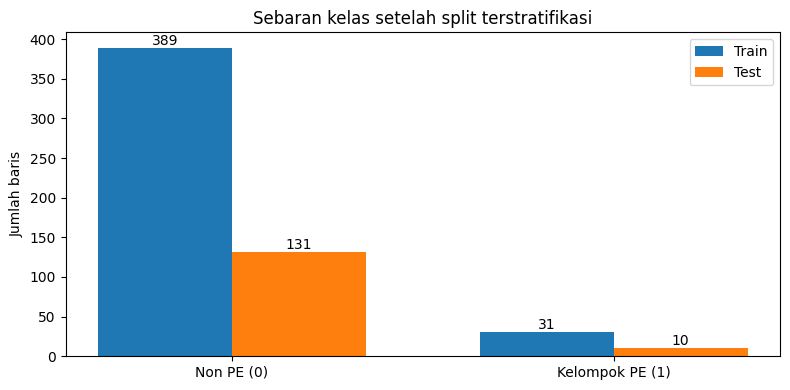

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
xpos = np.arange(2)
train_counts = y_train.value_counts().reindex([0, 1], fill_value=0)
test_counts = y_test.value_counts().reindex([0, 1], fill_value=0)
w = 0.35
ax.bar(xpos - w/2, train_counts.values, width=w, label='Train')
ax.bar(xpos + w/2, test_counts.values, width=w, label='Test')
ax.set_xticks(xpos, ['Non PE (0)', 'Kelompok PE (1)'])
ax.set_ylabel('Jumlah baris')
ax.set_title('Sebaran kelas setelah split terstratifikasi')
ax.legend()
for cont in ax.containers: ax.bar_label(cont)
plt.tight_layout()
plt.show()

## E. Merancang pipeline preprocessing dan Decision Tree

Bagian ini memakai metode yang *sama secara konsep* dengan `build_pipeline()` di sumber:

- **Numerik** (`USIA`, `PARITAS`): `SimpleImputer(strategy='median')`.
- **Kategorikal** (6 kolom): imputer modus, lalu `OneHotEncoder(handle_unknown='ignore')`.
- **Classifier:** Decision Tree `max_depth=3`, `min_samples_leaf=10`, `class_weight='balanced'`, `random_state=42`.

Imputasi dan encoding dijalankan di **dalam** pipeline sehingga saat `fit(X_train, y_train)` seluruh statistik hanya dipelajari dari train. Pohon keputusan tidak bergantung pada jarak Euclidean, sehingga StandardScaler/MinMaxScaler **bukan langkah wajib** di sini.

In [7]:
def make_preprocessor():
    """Buat transformer baru agar model eksperimen tidak berbagi state fitted."""
    numeric = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ])
    categorical = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])
    return ColumnTransformer(transformers=[
        ('num', numeric, NUMERIC),
        ('cat', categorical, CATEGORICAL)
    ])


def make_tree(**overrides):
    config = {'max_depth': 3, 'min_samples_leaf': 10,
              'class_weight': 'balanced', 'random_state': 42}
    config.update(overrides)
    return Pipeline(steps=[
        ('preprocess', make_preprocessor()),
        ('classifier', DecisionTreeClassifier(**config))
    ])

fixed_model = make_tree()
print(fixed_model)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['USIA', 'PARITAS']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['JARAK KELAHIRAN',
                                                   'RIW

### E1. Fit model hanya pada data training

Perhatikan bahwa objek transformer belum berisi median, modus dan vocabulary kategori sebelum `fit`. Informasi itu baru muncul setelah `.fit(X_train, y_train)`.

In [8]:
fixed_model.fit(X_train, y_train)
preprocess_fit = fixed_model.named_steps['preprocess']
feature_names = preprocess_fit.get_feature_names_out()

X_train_encoded = preprocess_fit.transform(X_train)
print('Input        :', X_train.shape, '(8 fitur)')
print('Train encoded:', X_train_encoded.shape)
assert np.isfinite(X_train_encoded).all()
print('Feature names:')
for i, term in enumerate(feature_names):
    print(f'{i:02d}  {term}')

Input        : (420, 8) (8 fitur)
Train encoded: (420, 15)
Feature names:
00  num__USIA
01  num__PARITAS
02  cat__JARAK KELAHIRAN_< 2 tahun
03  cat__JARAK KELAHIRAN_> 2 tahun
04  cat__JARAK KELAHIRAN_anak pertama
05  cat__RIW HIPERTENSI_Tidak
06  cat__RIW HIPERTENSI_Ya
07  cat__OBESITAS_Tidak
08  cat__OBESITAS_Ya
09  cat__RIW DM_Tidak
10  cat__RIW DM_Ya
11  cat__RIW HIPERTENSI/PE DALAM KELUARGA_Ada
12  cat__RIW HIPERTENSI/PE DALAM KELUARGA_Tidak
13  cat__SOSEK RENDAH_<UMR
14  cat__SOSEK RENDAH_>UMR


In [9]:
# Inspect satu baris: data mentah -> representasi numerik hasil pipeline
sample_idx = X_train.index[0]
print('Satu record training, sebelum transformasi:')
display(X_train.loc[[sample_idx]])
print('Satu record training, setelah transformasi:')
display(pd.DataFrame(
    preprocess_fit.transform(X_train.loc[[sample_idx]]),
    columns=feature_names, index=[sample_idx]
).T.rename(columns={sample_idx:'bobot_fitur'}))

Satu record training, sebelum transformasi:


,USIA,PARITAS,JARAK KELAHIRAN,RIW HIPERTENSI,OBESITAS,RIW DM,RIW HIPERTENSI/PE DALAM KELUARGA,SOSEK RENDAH
405,20.0,1.0,anak pertama,Tidak,Tidak,Tidak,Tidak,>UMR


Satu record training, setelah transformasi:


,bobot_fitur
num__USIA,20.0
num__PARITAS,1.0
cat__JARAK KELAHIRAN_< 2 tahun,0.0
cat__JARAK KELAHIRAN_> 2 tahun,0.0
cat__JARAK KELAHIRAN_anak pertama,1.0
cat__RIW HIPERTENSI_Tidak,1.0
cat__RIW HIPERTENSI_Ya,0.0
cat__OBESITAS_Tidak,1.0
cat__OBESITAS_Ya,0.0
cat__RIW DM_Tidak,1.0


### E2. Audit nilai imputasi yang hanya dipelajari dari train

Nilai-nilai ini **bukan** statistik seluruh dataset. Jika nanti data test atau data baru memiliki missing values, nilai dari train yang dipakai. Jenis kategori yang tidak dikenal encoder ditangani dengan `handle_unknown='ignore'` (blok dummy kategori itu dapat bernilai nol).

In [10]:
num_imputer = preprocess_fit.named_transformers_['num'].named_steps['imputer']
cat_imputer = preprocess_fit.named_transformers_['cat'].named_steps['imputer']
print('Median numerik TRAIN :', dict(zip(NUMERIC, num_imputer.statistics_)))
print('Modus kategorikal TRAIN:')
display(pd.DataFrame({'fitur':CATEGORICAL,'modus_train':cat_imputer.statistics_}))
print('Pemeriksaan missing sesudah transform:')
print('Jumlah nan encoded train:', int(np.isnan(X_train_encoded).sum()))

Median numerik TRAIN : {'USIA': np.float64(28.0), 'PARITAS': np.float64(2.0)}
Modus kategorikal TRAIN:


,fitur,modus_train
0,JARAK KELAHIRAN,anak pertama
1,RIW HIPERTENSI,Tidak
2,OBESITAS,Tidak
3,RIW DM,Tidak
4,RIW HIPERTENSI/PE DALAM KELUARGA,Tidak
5,SOSEK RENDAH,>UMR


Pemeriksaan missing sesudah transform:
Jumlah nan encoded train: 0


## F. Baseline dan metrik evaluasi

Untuk data tidak seimbang, akurasi saja dapat menyesatkan. *DummyClassifier* `most_frequent` selalu memilih kelas mayoritas. Untuk demonstrasi awal, kita bandingkan baseline dan pohon menggunakan **validation subset dari train**, bukan holdout test. Hanya pada Bagian H test dibuka untuk evaluasi akhir.

Konvensi confusion matrix: **baris = aktual**, **kolom = prediksi**; label positif adalah PE (`1`).

\[
\mathrm{Precision}_{PE}=\frac{TP}{TP+FP},\qquad
\mathrm{Recall}_{PE}=\frac{TP}{TP+FN}
\]
\[
\mathrm{Specificity}=\frac{TN}{TN+FP},\qquad
\mathrm{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}
\]
\[
F1_{PE}=\frac{2\,\mathrm{Precision}\,\mathrm{Recall}}{\mathrm{Precision}+\mathrm{Recall}}
\]

*Recall* tinggi berarti lebih banyak positif terdeteksi, tetapi tidak otomatis baik jika *false positives* terlalu banyak. Dalam data medis, pemilihan biaya kesalahan membutuhkan tujuan klinis yang belum ditentukan di studi kasus ini.

In [11]:
def evaluate_binary(y_true, y_pred):
    """Metrik untuk label positif 1, denominator nol ditangani eksplisit."""
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'precision_PE': precision_score(y_true, y_pred, zero_division=0),
        'recall_PE': recall_score(y_true, y_pred, zero_division=0),
        'f1_PE': f1_score(y_true, y_pred, zero_division=0),
        'specificity': tn / (tn + fp) if (tn + fp) > 0 else np.nan,
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    }

# Demonstrasi awal HANYA dari training set: buat validation subset internal.
X_dev, X_valid, y_dev, y_valid = train_test_split(
    X_train, y_train, test_size=0.25, random_state=21, stratify=y_train
)
baseline_dev = DummyClassifier(strategy='most_frequent').fit(X_dev,y_dev)
fixed_dev = make_tree().fit(X_dev,y_dev)
y_base_valid = baseline_dev.predict(X_valid)
y_fixed_valid = fixed_dev.predict(X_valid)
result_base_dev = evaluate_binary(y_valid,y_base_valid)
result_fixed_dev = evaluate_binary(y_valid,y_fixed_valid)
comparison_early = pd.DataFrame.from_dict({
    'Baseline mayoritas': result_base_dev,
    'Decision Tree awal': result_fixed_dev
},orient='index')
print('EVALUASI INTERNAL TRAIN — bukan holdout test')
display(comparison_early.round(3))

EVALUASI INTERNAL TRAIN — bukan holdout test


,accuracy,balanced_accuracy,precision_PE,recall_PE,f1_PE,specificity,TN,FP,FN,TP
Baseline mayoritas,0.924,0.500,0.00,0.00,0.000,1.000,97,0,8,0
Decision Tree awal,0.800,0.777,0.24,0.75,0.364,0.804,78,19,2,6


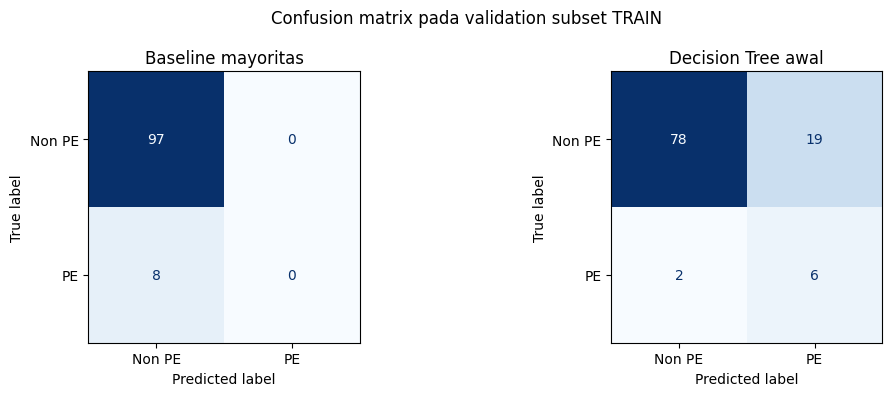

In [12]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax, pred, name in zip(axes,
                          [y_base_valid, y_fixed_valid],
                          ['Baseline mayoritas', 'Decision Tree awal']):
    ConfusionMatrixDisplay.from_predictions(
        y_valid, pred, labels=[0,1],
        display_labels=['Non PE','PE'],
        cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(name)
plt.suptitle('Confusion matrix pada validation subset TRAIN')
plt.tight_layout()
plt.show()

### F1. Contoh hitung manual — angka hipotetis

**Contoh latihan matematika saja (bukan hasil model pada data PE):** TN=80, FP=10, FN=4, TP=6.

- `Recall_PE = 6 / (6+4) = 0,60`.
- `Precision_PE = 6 / (6+10) = 0,375`.
- `Specificity = 80 / (80+10) ≈ 0,889`.
- `Accuracy = (80+6) / 100 = 0,86`.

Pada Bagian H, gunakan confusion matrix *holdout test* yang benar-benar diperoleh untuk menghitung kembali metrik hasil eksperimen.

In [13]:
# Pastikan implementasi metrik identik dengan helper asli,
# memakai validation subset TRAIN agar holdout test belum dibuka.
src = source_metrics(y_valid, y_fixed_valid)
for k in ['accuracy','precision_PE','recall_PE','f1_PE','specificity']:
    assert np.isclose(src[k], result_fixed_dev[k])
for k in ['TN','FP','FN','TP']:
    assert src[k] == result_fixed_dev[k]
print('Definisi metrik telah cocok dengan helper sumber (validation TRAIN).')

Definisi metrik telah cocok dengan helper sumber (validation TRAIN).


## G. Cross-validation — membandingkan konfigurasi pada train saja

**Alasan:** Jangan memilih parameter model berdasarkan skor *test*. Kita menggunakan `StratifiedKFold` dengan 5 lipatan pada train. Tiap pelatihan CV membangun `Pipeline` baru sehingga imputasi dan encoding hanya di-*fit* pada bagian training fold.

Di modul ini, metrik optimasi utama adalah **F1 kelas PE** sebagai contoh tujuan eksperimen, **bukan ambang kinerja klinis**. Kita juga memeriksa recall, precision dan balanced accuracy agar tidak terpaku pada satu metrik. Karena kasus positif sangat sedikit, skor antar-fold dapat bervariasi besar.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_metrics = {
    'accuracy': 'accuracy',
    'balanced_accuracy': 'balanced_accuracy',
    'precision_PE': 'precision',
    'recall_PE': 'recall',
    'f1_PE': 'f1'
}
fixed_cv = cross_validate(
    make_tree(), X_train, y_train, cv=cv, scoring=cv_metrics,
    return_train_score=False, n_jobs=1, error_score='raise'
)
cv_summary = pd.DataFrame({
    'metric': list(cv_metrics),
    'mean': [fixed_cv['test_'+m].mean() for m in cv_metrics],
    'std': [fixed_cv['test_'+m].std(ddof=1) for m in cv_metrics]
})
display(cv_summary.round(3))
print('CV hanya memakai',len(X_train),'baris training.')

,metric,mean,std
0,accuracy,0.845,0.039
1,balanced_accuracy,0.726,0.070
2,precision_PE,0.272,0.080
3,recall_PE,0.586,0.164
4,f1_PE,0.360,0.072


CV hanya memakai 420 baris training.


### G1. Pencarian parameter (GridSearchCV)

Kita menguji `max_depth`, `min_samples_leaf`, dan `class_weight`. Semuanya merupakan pengaturan **Decision Tree**, bukan parameter pada imputer. Nilai-nilai ini dipilih untuk latihan, bukan rekomendasi klinis.

**Penting:** Seluruh rangkaian `Pipeline` dimasukkan dalam GridSearch sehingga masing-masing fold melakukan preprocessing yang benar. `refit=True` melatih ulang konfigurasi terpilih memakai seluruh training set, **tanpa melihat test**.

In [15]:
param_grid = {
    'classifier__max_depth': [2, 3, 4],
    'classifier__min_samples_leaf': [5, 10, 20],
    'classifier__class_weight': [None, 'balanced']
}
search = GridSearchCV(
    estimator=make_tree(),
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=1,
    refit=True,
    return_train_score=True,
    error_score='raise'
)
search.fit(X_train, y_train)
print('Jumlah kombinasi:', len(search.cv_results_['params']))
print('Best params TRAIN CV:', search.best_params_)
print('Mean CV F1 PE terbaik:',round(search.best_score_,3))
final_model = search.best_estimator_

Jumlah kombinasi: 18
Best params TRAIN CV: {'classifier__class_weight': 'balanced', 'classifier__max_depth': 2, 'classifier__min_samples_leaf': 5}
Mean CV F1 PE terbaik: 0.454


,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_classifier__max_depth,param_classifier__min_samples_leaf,param_classifier__class_weight
9,1,0.454,0.112,0.546,2,5,balanced
12,2,0.413,0.107,0.501,3,5,balanced
15,3,0.399,0.106,0.487,4,5,balanced
3,4,0.384,0.130,0.528,3,5,None
16,5,0.364,0.084,0.442,4,10,balanced
13,6,0.360,0.064,0.454,3,10,balanced
1,7,0.348,0.110,0.483,2,10,None
14,8,0.345,0.084,0.397,3,20,balanced
10,9,0.340,0.029,0.412,2,10,balanced
11,10,0.337,0.031,0.403,2,20,balanced


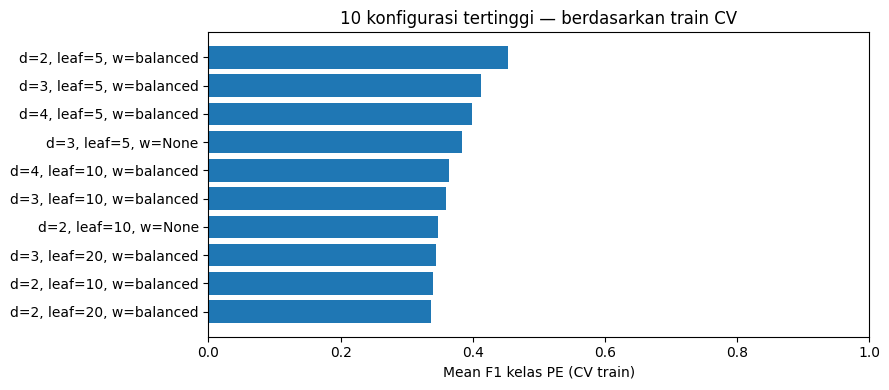

In [16]:
cv_results = pd.DataFrame(search.cv_results_)
cols_cv = ['rank_test_score','mean_test_score','std_test_score',
           'mean_train_score','param_classifier__max_depth',
           'param_classifier__min_samples_leaf','param_classifier__class_weight']
ranked = cv_results[cols_cv].sort_values(
    ['rank_test_score','mean_test_score'], ascending=[True,False]
)
display(ranked.head(12).round(3))

fig, ax = plt.subplots(figsize=(9,4))
view = ranked.head(10).sort_values('mean_test_score')
names = [f"d={a}, leaf={b}, w={c}" for a,b,c in zip(
    view['param_classifier__max_depth'],
    view['param_classifier__min_samples_leaf'],
    view['param_classifier__class_weight'])]
ax.barh(names, view['mean_test_score'])
ax.set_xlabel('Mean F1 kelas PE (CV train)')
ax.set_title('10 konfigurasi tertinggi — berdasarkan train CV')
ax.set_xlim(0,1)
plt.tight_layout();plt.show()

### G2. Refleksi hasil cross-validation

Bandingkan `mean_train_score` terhadap `mean_test_score`. Jika training score jauh lebih tinggi, model berpotensi *overfit*; tetapi beda skor saja tidak membuktikan penyebabnya. Karena jumlah kelas PE kecil, rentang skor antar-fold dapat besar. Pemilihan konfigurasi berdasarkan CV belum sama dengan validasi eksternal.

## H. Evaluasi akhir pada holdout test

Tahap ini baru dilakukan setelah konfigurasi dipilih melalui CV train. Test **tidak** dipakai lagi untuk mengubah konfigurasi pada modul ini. Selain model hasil pencarian parameter, kita pertahankan skor *fixed model* sumber sebagai pembanding transparan.

**Hasil test satu split** merupakan ilustrasi; belum ada interval kepercayaan, uji lintas-situs, atau pemisahan tingkat pasien yang terverifikasi.

In [17]:
# Tahap pertama yang memakai HOLDOUT TEST untuk evaluasi model.
# Baseline dan fixed model sudah fit pada X_train, tanpa mengakses label test.
X_test_encoded = fixed_model.named_steps["preprocess"].transform(X_test)
assert X_test_encoded.shape[1] == X_train_encoded.shape[1]
assert np.isfinite(X_test_encoded).all()
print("Encoded test shape:", X_test_encoded.shape)
baseline = DummyClassifier(strategy='most_frequent').fit(X_train,y_train)
y_pred_base = baseline.predict(X_test)
y_pred_fixed = fixed_model.predict(X_test)
result_base = evaluate_binary(y_test,y_pred_base)
result_fixed = evaluate_binary(y_test,y_pred_fixed)

y_pred_final = final_model.predict(X_test)
y_score_final = final_model.predict_proba(X_test)[:,list(final_model.classes_).index(1)]
result_final = evaluate_binary(y_test, y_pred_final)

comparison = pd.DataFrame.from_dict({
    'Baseline mayoritas': result_base,
    'Pohon sumber (fixed)': result_fixed,
    'Pohon terpilih via CV': result_final
}, orient='index')
display(comparison.round(3))
print('\nClassification report model terpilih:')
print(classification_report(y_test, y_pred_final,
    labels=[0,1], target_names=['Non PE','Kelompok PE'], zero_division=0))
print('Matriks pohon sumber pada test:',
      {k:result_fixed[k] for k in ['TN','FP','FN','TP']})
print('Metrik sumber konsisten:',
      all(np.isclose(source_metrics(y_test,y_pred_fixed)[k],result_fixed[k])
          for k in ['accuracy','precision_PE','recall_PE','f1_PE','specificity']))

Encoded test shape: (141, 15)


,accuracy,balanced_accuracy,precision_PE,recall_PE,f1_PE,specificity,TN,FP,FN,TP
Baseline mayoritas,0.929,0.500,0.000,0.0,0.000,1.000,131,0,10,0
Pohon sumber (fixed),0.823,0.766,0.241,0.7,0.359,0.832,109,22,3,7
Pohon terpilih via CV,0.922,0.819,0.467,0.7,0.560,0.939,123,8,3,7



Classification report model terpilih:
              precision    recall  f1-score   support

      Non PE       0.98      0.94      0.96       131
 Kelompok PE       0.47      0.70      0.56        10

    accuracy                           0.92       141
   macro avg       0.72      0.82      0.76       141
weighted avg       0.94      0.92      0.93       141

Matriks pohon sumber pada test: {'TN': 109, 'FP': 22, 'FN': 3, 'TP': 7}
Metrik sumber konsisten: True


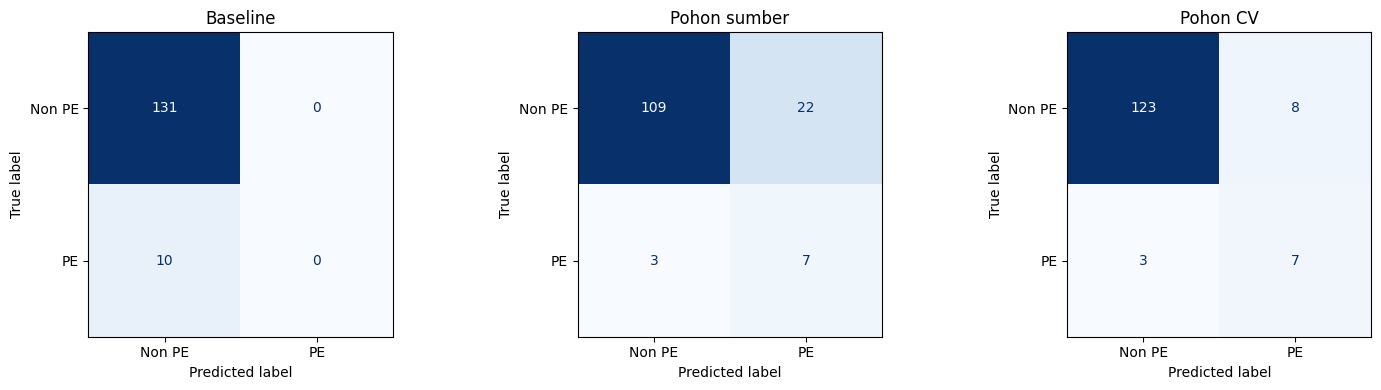

In [18]:
fig, axes = plt.subplots(1,3,figsize=(15,4))
for ax, pred, name in zip(axes,
    [y_pred_base,y_pred_fixed,y_pred_final],
    ['Baseline', 'Pohon sumber', 'Pohon CV']):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0,1], display_labels=['Non PE','PE'],
        cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name)
plt.tight_layout();plt.show()

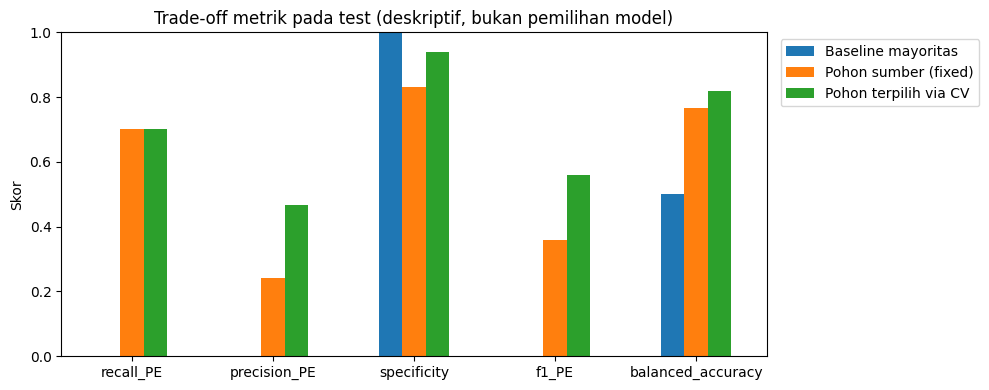

In [19]:
metrics_plot = ['recall_PE','precision_PE','specificity','f1_PE','balanced_accuracy']
comparison[metrics_plot].T.plot(kind='bar',figsize=(10,4),rot=0)
plt.ylim(0,1)
plt.ylabel('Skor')
plt.title('Trade-off metrik pada test (deskriptif, bukan pemilihan model)')
plt.legend(loc='upper left',bbox_to_anchor=(1.01,1))
plt.tight_layout();plt.show()

### H1. Precision–Recall dan ROC: pembacaan hati-hati

Kurva berikut menggambarkan kemampuan mengurutkan skor **pada test yang sama**. Pada kelas positif yang sedikit, **Precision–Recall** sering lebih informatif daripada accuracy. Skor `predict_proba` dari pohon dengan `class_weight` **tidak otomatis terkalibrasi** menjadi probabilitas kejadian PE.

**Jangan** memilih threshold berdasarkan kurva test ini dan lalu mengklaim performa test tetap tidak bias. Penyesuaian threshold/kalibrasi membutuhkan desain validasi tambahan di train.

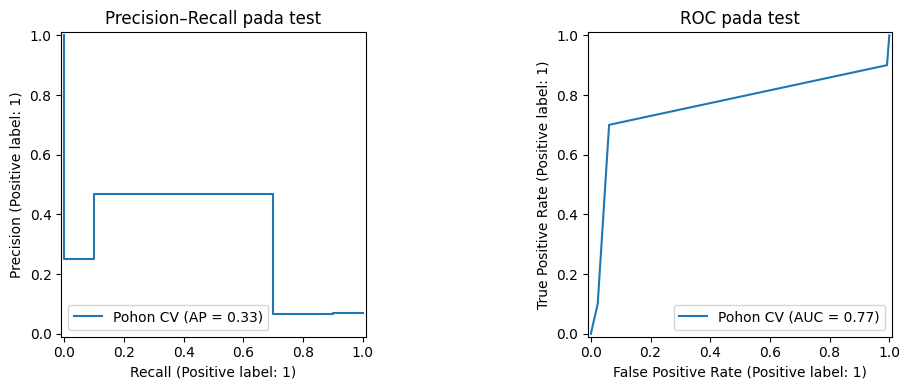

In [20]:
fig, axes = plt.subplots(1,2,figsize=(11,4))
PrecisionRecallDisplay.from_predictions(y_test,y_score_final,
    name='Pohon CV', ax=axes[0])
axes[0].set_title('Precision–Recall pada test')
RocCurveDisplay.from_predictions(y_test,y_score_final,
    name='Pohon CV', ax=axes[1])
axes[1].set_title('ROC pada test')
plt.tight_layout();plt.show()

## I. Menafsirkan model dan *error analysis*

Decision Tree mempelajari aturan pada **fitur yang sudah di-encode**. Angka jumlah sampel/bobot di simpul harus dibaca sesuai `class_weight` yang terpilih: `value` dapat mencerminkan bobot yang bukan hitungan mentah.

*Feature importance* menggambarkan kontribusi pada keputusan pohon dalam data ini, **bukan** bukti hubungan kausal maupun faktor risiko klinis.

Kedalaman aktual: 2 | Daun: 4


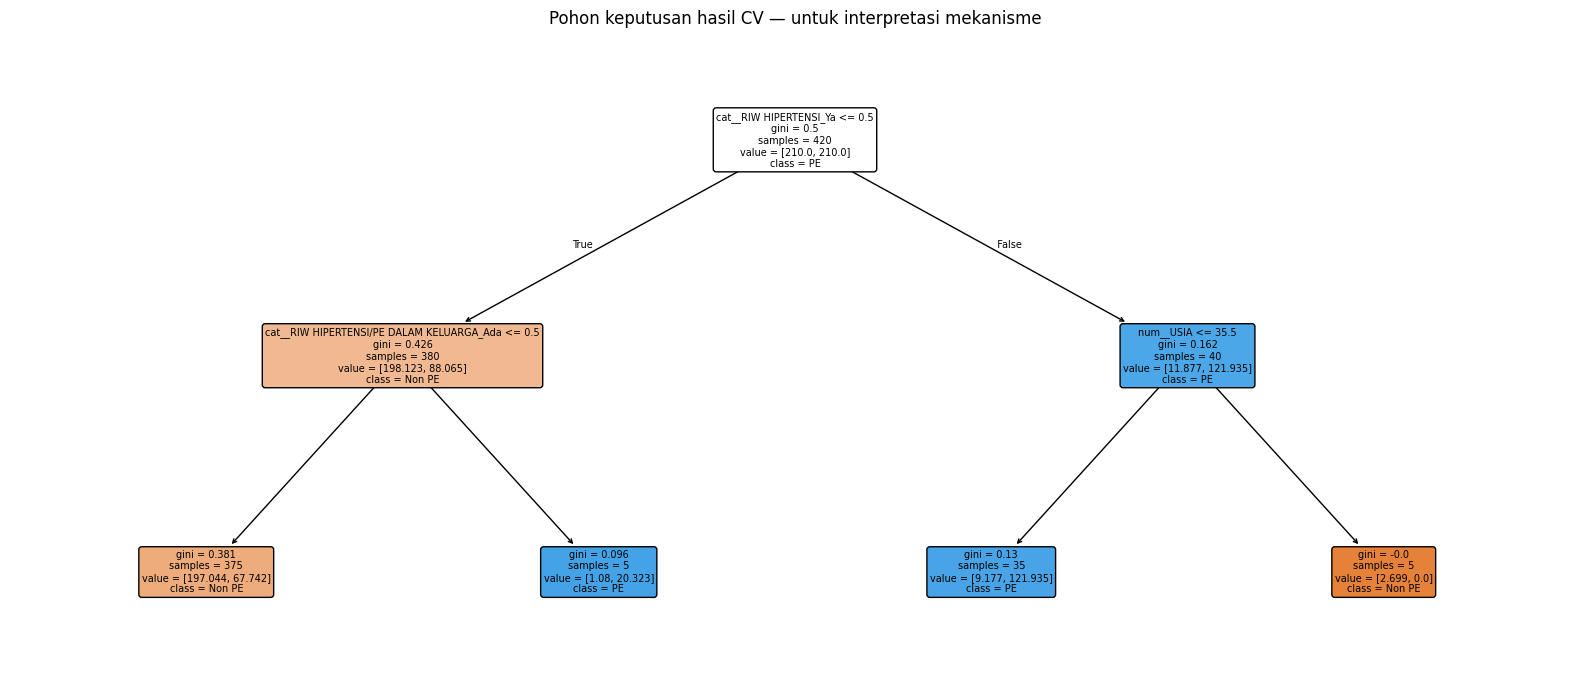

Aturan teks (maksimal depth=3 untuk tampilan ringkas):
|--- cat__RIW HIPERTENSI_Ya <= 0.50
|   |--- cat__RIW HIPERTENSI/PE DALAM KELUARGA_Ada <= 0.50
|   |   |--- class: 0
|   |--- cat__RIW HIPERTENSI/PE DALAM KELUARGA_Ada >  0.50
|   |   |--- class: 1
|--- cat__RIW HIPERTENSI_Ya >  0.50
|   |--- num__USIA <= 35.50
|   |   |--- class: 1
|   |--- num__USIA >  35.50
|   |   |--- class: 0



In [21]:
trained_tree = final_model.named_steps['classifier']
final_names = final_model.named_steps['preprocess'].get_feature_names_out()
print('Kedalaman aktual:', trained_tree.get_depth(), '| Daun:', trained_tree.get_n_leaves())

fig,ax = plt.subplots(figsize=(16,7))
plot_tree(trained_tree, feature_names=final_names,
          class_names=['Non PE','PE'], filled=True,
          rounded=True, fontsize=7, ax=ax)
ax.set_title('Pohon keputusan hasil CV — untuk interpretasi mekanisme')
plt.tight_layout();plt.show()

print('Aturan teks (maksimal depth=3 untuk tampilan ringkas):')
print(export_text(trained_tree, feature_names=list(final_names), max_depth=3))

Jumlah feature importance: 1.0


,importance
cat__RIW HIPERTENSI_Ya,0.737570
cat__RIW HIPERTENSI/PE DALAM KELUARGA_Ada,0.211630
num__USIA,0.050801


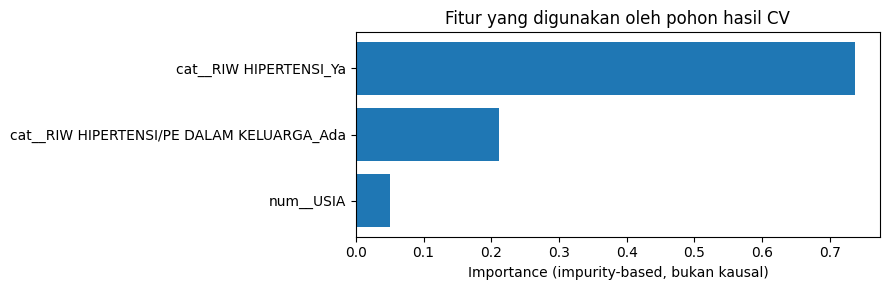

In [22]:
feature_importance = pd.Series(
    trained_tree.feature_importances_, index=final_names
).sort_values(ascending=False)
print('Jumlah feature importance:',round(feature_importance.sum(),4))
display(feature_importance[feature_importance>0].to_frame('importance'))

active = feature_importance[feature_importance>0].sort_values().tail(12)
fig,ax=plt.subplots(figsize=(9,max(3,0.4*len(active)+1)))
ax.barh(active.index,active.values)
ax.set_xlabel('Importance (impurity-based, bukan kausal)')
ax.set_title('Fitur yang digunakan oleh pohon hasil CV')
plt.tight_layout();plt.show()

### I1. Audit salah prediksi tanpa menampilkan pengenal pasien

Kita simpan hanya indeks baris sumber (untuk audit internal), target aktual, prediksi, dan skor model. Hindari menampilkan kolom pengenal langsung atau catatan bebas dari workbook asli.

- **FP**: aktual Non PE tetapi diprediksi PE.
- **FN**: aktual PE tetapi diprediksi Non PE.
- Jika FN kecil namun FP besar, model menangkap lebih banyak positif dengan konsekuensi alarm salah; penilaian konsekuensi klinis berada di luar praktik ini.

In [23]:
error_table = pd.DataFrame({
    'baris_sumber_excel_perkiraan': X_test.index.to_numpy() + 2,
    'aktual': y_test.to_numpy(),
    'prediksi': y_pred_final,
    'skor_model_PE': y_score_final
}, index=X_test.index)
error_table['status'] = np.select([
    (error_table.aktual==0)&(error_table.prediksi==0),
    (error_table.aktual==0)&(error_table.prediksi==1),
    (error_table.aktual==1)&(error_table.prediksi==0),
    (error_table.aktual==1)&(error_table.prediksi==1),
],['TN','FP','FN','TP'],default='?')
print('Distribusi status prediksi:')
display(error_table.status.value_counts().reindex(['TN','FP','FN','TP'],fill_value=0).to_frame('n'))
print('Pratinjau beberapa baris salah prediksi (tanpa nama):')
display(error_table.loc[error_table.status.isin(['FP','FN'])].head(10))

Distribusi status prediksi:


,n
status,
TN,123
FP,8
FN,3
TP,7


Pratinjau beberapa baris salah prediksi (tanpa nama):


,baris_sumber_excel_perkiraan,aktual,prediksi,skor_model_PE,status
199,201,0,1,0.930004,FP
404,406,1,0,0.255837,FN
171,173,0,1,0.949552,FP
93,95,0,1,0.949552,FP
257,259,0,1,0.930004,FP
458,460,0,1,0.949552,FP
554,556,1,0,0.000000,FN
225,227,1,0,0.255837,FN
227,229,0,1,0.930004,FP
255,257,0,1,0.930004,FP


## J. Membaca batasan metodologi dan risiko bias

1. **Ukuran efektif sampel positif:** 41 baris kelompok PE keseluruhan; sekitar 10 pada test. Satu perubahan prediksi mengubah recall test sekitar 10 poin persentase.
2. **Independensi tidak teruji:** nomor rekam medis/ID pasien unik dan identifikasi kunjungan berulang tidak terverifikasi.
3. **Waktu prediktor dan label tidak teruji:** risiko *temporal leakage*, terutama untuk variabel yang mungkin dicatat setelah kejadian.
4. **Imbalance:** sekitar 7% kelas positif; accuracy tinggi bisa terjadi dengan memprediksi mayoritas.
5. **Penyederhanaan label:** tipe PE/PEB/Eklampsia digabung hanya untuk latihan target biner sesuai sumber.
6. **Single source / single split:** bukan bukti generalisasi; butuh audit data, validasi eksternal, pengukuran uncertainty dan review klinis sebelum penelitian lanjutan.
7. **Probabilitas tidak terkalibrasi:** skor model tidak boleh dipakai sebagai estimasi risiko pasien.

**Kesimpulan yang sah:** notebook menunjukkan alur metodologis klasifikasi dan evaluasi pada data latihan. **Kesimpulan yang tidak sah:** model akurat untuk diagnosa atau layak diterapkan di fasilitas kesehatan.

## K. Ekspor hasil analisis untuk Praktikum 07

Kita menyimpan **tabel metrik, hasil prediksi, ringkasan pencarian parameter, serta metadata eksperimen**. Ekspor model `.joblib` dan verifikasi *reload* disiapkan untuk Praktikum 07 supaya kompetensi antar-modul tidak berulang. Hasil disimpan di `studi_kasus/hasil/`.

In [24]:
comparison.round(6).to_csv(OUTPUT/'metrik_perbandingan.csv', index_label='model')
error_table.to_csv(OUTPUT/'prediksi_test.csv', index=False)
ranked.to_csv(OUTPUT/'ringkasan_cv.csv', index=False)

report = {
    'module': 'Praktikum 06 — Pipeline dan Evaluasi PE',
    'data_source': 'data_bersih.csv dari Praktikum 05',
    'total_records': int(len(X)),
    'train_records': int(len(X_train)),
    'test_records': int(len(X_test)),
    'class_train': {str(k):int(v) for k,v in y_train.value_counts().items()},
    'class_test': {str(k):int(v) for k,v in y_test.value_counts().items()},
    'features': FEATURES,
    'positive_label': 1,
    'split': {'test_size':0.25,'stratify':True,'random_state':42},
    'cv': {'n_splits':5,'shuffle':True,'random_state':42,
           'scoring_for_selection':'f1_PE'},
    'best_cv_f1_PE': float(search.best_score_),
    'best_params': {k:(int(v) if isinstance(v,np.integer) else v)
                    for k,v in search.best_params_.items()},
    'test_metrics': {name: {k:(int(v) if k in ['TN','FP','FN','TP'] else float(v))
                    for k,v in vals.items()}
                    for name,vals in [('baseline',result_base),
                                     ('fixed',result_fixed),('selected',result_final)]},
    'library_versions': {'python': platform.python_version(),
                         'scikit_learn': sklearn.__version__,
                         'pandas': pd.__version__},
    'limitations': [
        'Row-level split; patient-level independence not verified',
        'Predictor timing and outcome definitions not clinically audited',
        'Small number of positive cases; no external validation',
        'Predicted scores are not calibrated clinical risk',
        'Educational use only; not for diagnosis or clinical decisions'
    ]
}
(OUTPUT/'laporan_praktikum06.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding='utf-8'
)
print('Artefak tersimpan:')
for p in sorted(OUTPUT.glob('*')):
    print('-',p.name, f'({p.stat().st_size:,} bytes)')

Artefak tersimpan:
- laporan_praktikum06.json (2,206 bytes)
- metrik_perbandingan.csv (303 bytes)
- prediksi_test.csv (4,361 bytes)
- ringkasan_cv.csv (1,291 bytes)


### K1. Verifikasi output dan *reproducibility*

Pemeriksaan sederhana: semua baris test memiliki prediksi, tidak ada NaN skor, metrik dapat direproduksi dari CSV, dan berkas konfigurasi bisa dibaca ulang.

In [25]:
saved_pred = pd.read_csv(OUTPUT/'prediksi_test.csv')
saved_report = json.loads((OUTPUT/'laporan_praktikum06.json').read_text(encoding='utf-8'))
assert len(saved_pred) == len(y_test)
assert saved_pred[['aktual','prediksi','skor_model_PE']].notna().all().all()
check = evaluate_binary(saved_pred['aktual'], saved_pred['prediksi'])
assert check['TP'] == result_final['TP'] and check['FN'] == result_final['FN']
assert saved_report['train_records'] + saved_report['test_records'] == len(X)
print('OK: seluruh artefak ekspor konsisten dan dapat dibaca ulang.')

OK: seluruh artefak ekspor konsisten dan dapat dibaca ulang.


# Latihan mandiri — kerjakan sebelum membuka kunci jawaban

## L. Soal konseptual (12 soal)

1. Mengapa `stratify=y` digunakan untuk data dengan kelas positif sedikit?
2. Mengapa median/modus perlu dihitung dari train saja, bukan dari semua data?
3. Apa perbedaan `Pipeline` dengan sekadar menjalankan beberapa transformasi terpisah?
4. Mengapa StandardScaler tidak wajib pada Decision Tree?
5. Jelaskan makna `class_weight='balanced'` dan apa yang **tidak** dijaminnya.
6. Dari TN=109, FP=22, FN=3, TP=7, hitung accuracy dan recall PE.
7. Mengapa baseline mayoritas bisa memiliki accuracy tinggi namun recall PE nol?
8. Bedakan *false negative* dengan *false positive* dalam target yang digunakan.
9. Apa tujuan 5-fold stratified CV, dan dataset mana yang boleh dipakai?
10. Apa beda *mean CV F1* dengan *test F1*? Bolehkah dipilih nilai terbaik berdasarkan test?
11. Mengapa importance pada pohon tidak dapat dianggap sebagai faktor risiko klinis yang kausal?
12. Sebutkan tiga alasan mengapa model ini belum siap untuk diterapkan pada pasien.

## M. Latihan kode (10 soal)

Gunakan variabel dari bagian sebelumnya; buat jawaban sendiri sebelum membandingkan dengan kunci.

1. Hitung presentase kelas PE dalam train dan test.
2. Tampilkan median `USIA` pada train dan bandingkan nilai yang dipelajari imputer.
3. Tampilkan nama lengkap fitur setelah One-Hot Encoding dan jumlahnya.
4. Buat fungsi yang menghitung sensitivity dan specificity dari empat angka confusion matrix.
5. Tampilkan 5-fold skor F1 kelas PE untuk Decision Tree `max_depth=2`, `min_samples_leaf=10`, `class_weight='balanced'`.
6. Evaluasi model tree dengan `class_weight=None` **menggunakan CV train saja**.
7. Ambil 3 sampel test dan tampilkan aktual vs prediksi final tanpa nama individu.
8. Hitung jumlah FP dan FN dari tabel ekspor `prediksi_test.csv`.
9. Tampilkan hanya 5 fitur dengan importance tertinggi (boleh nol bila pohon sederhana).
10. Verifikasi jumlah kelas positif test sama dengan `TP+FN`.

## N. Tantangan terapan (3 tugas)

**T1 — Perbandingan dua konfigurasi:** Gunakan stratified CV pada train untuk membandingkan pohon dangkal dan pohon lebih dalam; bahas trade-off dan variabilitas F1.

**T2 — Analisis kesalahan:** Jelaskan perbedaan FP/FN dalam *confusion matrix* aktual; tampilkan rasio error tanpa mengidentifikasi orang.

**T3 — Audit risiko generalisasi:** Buat checklist eksperimen yang menyebutkan kebocoran, kelas tidak seimbang, temporalitas, independensi pasien dan validasi eksternal. Mana yang sudah dipenuhi, mana yang belum?

---

# Kunci jawaban dan pembahasan

> Bagian O–Q disediakan sebagai **kunci pengajar dan bahan belajar mandiri**, bukan langkah yang harus disalin tanpa dipahami. Jawaban numerik dapat bergeser jika data atau versi pustaka berbeda; gunakan nilai yang benar-benar keluar dari notebook.

## O. Jawaban soal konseptual

1. Stratifikasi menjaga proporsi minoritas tetap terwakili pada train dan test; tidak membuat observasi independen.
2. Menggunakan statistik semua data sebelum split menyampaikan informasi dari test ke training (*leakage*).
3. Pipeline mengikat urutan `fit`/`transform` sehingga setiap fold mengestimasi preprocessing hanya dari data latihnya.
4. Pohon memecah data dengan ambang fitur; tidak membandingkan jarak seperti k-NN.
5. `balanced` memberi bobot lebih tinggi untuk kelas yang jarang muncul dalam train; tidak menjamin recall tinggi, kalibrasi probabilitas, atau keadilan hasil.
6. Accuracy = `(109+7)/141 ≈ 0,823`; recall PE = `7/10 = 0,70`.
7. Dominasi kelas Non PE membuat prediksi semua negatif sering benar secara total tetapi tidak menemukan PE.
8. FN: PE sebenarnya tetapi prediksi Non PE; FP: Non PE sebenarnya tetapi prediksi PE.
9. CV membagi **train** menjadi lima subset validasi bergiliran untuk menilai variasi model tanpa menggunakan test.
10. CV F1 dipakai memilih konfigurasi; test F1 adalah evaluasi akhir yang baru dibuka setelah pemilihan. Test tidak boleh menjadi alat memilih hyperparameter.
11. Importance hanya menjelaskan pengurangan impurity pada pohon terlatih; dapat dipengaruhi distribusi data, korelasi, dan bias encoding.
12. Contoh: independensi pasien tidak diketahui, 10 PE pada test sangat sedikit, prediktor dan label belum divalidasi temporal/klinis, tidak ada eksternal holdout ataupun kalibrasi.

## P. Jawaban latihan kode

Jawaban kode berikut menggunakan ulang variabel `X_train`, `X_test`, `y_train`, `y_test`, `fixed_model`, `final_model` dan `OUTPUT`. Semua sel dapat dijalankan setelah bagian A–K.

In [26]:
# M1. Proporsi kelas PE
display(pd.DataFrame({
    'subset':['Train','Test'],
    'n':[len(y_train),len(y_test)],
    'PE_n':[(y_train==1).sum(),(y_test==1).sum()],
    'PE_%':[round(100*(y_train==1).mean(),2),round(100*(y_test==1).mean(),2)]
}))

,subset,n,PE_n,PE_%
0,Train,420,31,7.38
1,Test,141,10,7.09


In [27]:
# M2. Median usia train dan median yang tersimpan dalam imputer
median_manual = X_train['USIA'].median()
median_model = dict(zip(NUMERIC,num_imputer.statistics_))['USIA']
print('Median manual TRAIN:',median_manual)
print('Median pada imputer:',median_model)
assert np.isclose(median_manual,median_model)

Median manual TRAIN: 28.0
Median pada imputer: 28.0


In [28]:
# M3. Nama fitur hasil encoder
feature_table = pd.DataFrame({'feature_id':range(len(feature_names)),
                              'feature_name':feature_names})
display(feature_table)
print('Total encoded features:',len(feature_table))

,feature_id,feature_name
0,0,num__USIA
1,1,num__PARITAS
2,2,cat__JARAK KELAHIRAN_< 2 tahun
3,3,cat__JARAK KELAHIRAN_> 2 tahun
4,4,cat__JARAK KELAHIRAN_anak pertama
5,5,cat__RIW HIPERTENSI_Tidak
6,6,cat__RIW HIPERTENSI_Ya
7,7,cat__OBESITAS_Tidak
8,8,cat__OBESITAS_Ya
9,9,cat__RIW DM_Tidak


Total encoded features: 15


In [29]:
# M4. Sensitivity / specificity dari confusion matrix
def sensitivity_specificity(tn,fp,fn,tp):
    sensitivity = tp/(tp+fn) if tp+fn else np.nan
    specificity = tn/(tn+fp) if tn+fp else np.nan
    return sensitivity, specificity
sensitivity, specificity = sensitivity_specificity(**{
    k.lower(): result_fixed[k] for k in ['TN','FP','FN','TP']})
print('Recall/Sensitivity PE:',round(sensitivity,3))
print('Specificity Non PE:',round(specificity,3))

Recall/Sensitivity PE: 0.7
Specificity Non PE: 0.832


In [30]:
# M5. F1 tiap lipatan: pohon kedalaman 2
shallow_cv = cross_validate(make_tree(max_depth=2,min_samples_leaf=10,
                                     class_weight='balanced'),
                            X_train,y_train,cv=cv,scoring={'f1':'f1'},n_jobs=1)
print('5 skor F1 PE:',np.round(shallow_cv['test_f1'],3))
print('Rata-rata:',round(shallow_cv['test_f1'].mean(),3))

5 skor F1 PE: [0.381 0.333 0.3   0.323 0.364]
Rata-rata: 0.34


In [31]:
# M6. Bandingkan class_weight=None vs balanced pada TRAIN CV
rows=[]
for weights in [None,'balanced']:
    s = cross_validate(make_tree(class_weight=weights),
                       X_train,y_train,cv=cv,scoring={'f1':'f1','recall':'recall'},n_jobs=1)
    rows.append({'class_weight':str(weights),'cv_f1_mean':s['test_f1'].mean(),
                 'cv_recall_mean':s['test_recall'].mean()})
display(pd.DataFrame(rows).round(3))

,class_weight,cv_f1_mean,cv_recall_mean
0,None,0.328,0.290
1,balanced,0.360,0.586


In [32]:
# M7. Tiga sampel holdout (tanpa nama atau fitur identitas)
display(pd.DataFrame({
    'aktual':y_test.iloc[:3].to_numpy(),
    'prediksi':y_pred_final[:3],
    'skor_model_PE':np.round(y_score_final[:3],3)
}))

,aktual,prediksi,skor_model_PE
0,0,0,0.256
1,0,0,0.256
2,0,0,0.256


In [33]:
# M8. Hitung FP & FN dari CSV ekspor
pred_csv = pd.read_csv(OUTPUT/'prediksi_test.csv')
print('FP =',((pred_csv.aktual==0)&(pred_csv.prediksi==1)).sum())
print('FN =',((pred_csv.aktual==1)&(pred_csv.prediksi==0)).sum())

FP = 8
FN = 3


In [34]:
# M9. Top 5 feature importance; interpretasi hanya teknis
display(feature_importance.head(5).to_frame('importance'))

,importance
cat__RIW HIPERTENSI_Ya,0.737570
cat__RIW HIPERTENSI/PE DALAM KELUARGA_Ada,0.211630
num__USIA,0.050801
num__PARITAS,0.000000
cat__JARAK KELAHIRAN_< 2 tahun,0.000000


In [35]:
# M10. Konsistensi jumlah PE pada test
n_positive_test = (y_test==1).sum()
assert n_positive_test == result_final['TP'] + result_final['FN']
print('PE aktual:',n_positive_test,'= TP',result_final['TP'],'+ FN',result_final['FN'])

PE aktual: 10 = TP 7 + FN 3


## Q. Jawaban tantangan terapan

**T1 — Solusi:** Uji dua konfigurasi pada CV training saja. Hindari menyimpulkan bahwa model dengan mean F1 sedikit lebih tinggi pasti lebih baik; perhatikan variasi skor dan jumlah PE per fold.

**T2 — Solusi:** Hitung proporsi FP dari seluruh negatif dan FN dari seluruh positif. Rasio ini merupakan statistik pada holdout yang kecil, bukan angka sensitivitas/spesifisitas populasi.

**T3 — Solusi:** Checklist: preprocessing di dalam Pipeline (**terpenuhi**), split sebelum fit (**terpenuhi**), CV pada train (**terpenuhi**), independensi pasien (**belum terverifikasi**), temporalitas prediktor/target (**belum terverifikasi**), validasi eksternal (**belum dilakukan**), klinis dan kalibrasi (**belum dilakukan**).

In [36]:
# T1. Dua konfigurasi diuji hanya di train CV
configs = {
    'dangkal': make_tree(max_depth=2,min_samples_leaf=20),
    'lebih_dalam': make_tree(max_depth=4,min_samples_leaf=5)
}
rows=[]
for name, model in configs.items():
    scores = cross_validate(model,X_train,y_train,cv=cv,
                            scoring={'f1':'f1','recall':'recall'},n_jobs=1)
    rows.append({'konfigurasi':name,
                 'mean_F1_PE':scores['test_f1'].mean(),
                 'SD_F1_PE':scores['test_f1'].std(ddof=1),
                 'mean_recall_PE':scores['test_recall'].mean()})
display(pd.DataFrame(rows).round(3))

,konfigurasi,mean_F1_PE,SD_F1_PE,mean_recall_PE
0,dangkal,0.337,0.034,0.614
1,lebih_dalam,0.399,0.119,0.681


In [37]:
# T2. Proporsi salah prediksi menurut kelas aktual
errors_by_class=pd.DataFrame({
    'kategori_error':['FP dari seluruh Non PE','FN dari seluruh PE'],
    'jumlah_error':[result_final['FP'],result_final['FN']],
    'jumlah_aktual':[(y_test==0).sum(),(y_test==1).sum()]
})
errors_by_class['rasio'] = (
    errors_by_class['jumlah_error']/errors_by_class['jumlah_aktual']
).round(3)
display(errors_by_class)

,kategori_error,jumlah_error,jumlah_aktual,rasio
0,FP dari seluruh Non PE,8,131,0.061
1,FN dari seluruh PE,3,10,0.300


In [38]:
# T3. Checklist kualitas rancangan evaluasi
checklist=pd.DataFrame([
    ('Train/test split sebelum fit','Terpenuhi'),
    ('Imputer dan OHE hanya fit train / fold','Terpenuhi'),
    ('CV untuk hyperparameter hanya pada train','Terpenuhi'),
    ('ID pasien unik dan split patient-level','Belum diverifikasi'),
    ('Waktu pencatatan prediktor dan outcome','Belum diverifikasi'),
    ('Validasi eksternal dan pengujian prospektif','Belum dilakukan'),
    ('Kalibrasi skor dan ambang klinis','Belum dilakukan')
],columns=['kriteria','status'])
display(checklist)

,kriteria,status
0,Train/test split sebelum fit,Terpenuhi
1,Imputer dan OHE hanya fit train / fold,Terpenuhi
2,CV untuk hyperparameter hanya pada train,Terpenuhi
3,ID pasien unik dan split patient-level,Belum diverifikasi
4,Waktu pencatatan prediktor dan outcome,Belum diverifikasi
5,Validasi eksternal dan pengujian prospektif,Belum dilakukan
6,Kalibrasi skor dan ambang klinis,Belum dilakukan


## R. Rangkuman dan persiapan Praktikum 07

**Hal yang harus dikuasai:**

- Kelas PE minoritas; accuracy tidak cukup. Selalu laporkan confusion matrix serta recall, precision, F1, specificity, dan jumlah kasus positif.
- Seluruh `fit` transformer berada di train atau training fold; test dipakai sekali untuk evaluasi akhir.
- `GridSearchCV` memilih konfigurasi menggunakan **F1 kelas PE** pada train, bukan memaksimalkan hasil test.
- Interpretasi pohon bersifat teknis dan tidak membuktikan hubungan sebab-akibat.
- Dataset dan desain split ini memiliki batasan serius; semua skor merupakan demonstrasi edukatif.

**Ke Praktikum 07:** gunakan `final_model`, konfigurasi terpilih, dan metadata evaluasi untuk mempelajari `joblib.dump`, `joblib.load`, verifikasi kesamaan prediksi sebelum/sesudah reload, serta *model card*. Jangan memakainya untuk layanan klinis.

**Checklist sebelum mengakhiri:** pastikan `Restart Kernel → Run All` berhasil dan empat artefak output terisi. Anda dapat mengekspor ringkasan eksperimen ke laporan praktikum.